In [59]:
#import packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import src.helperFunctions as hf

First, we'll read the data in. It comes from a tutorial on gathering data, but the final dataset is on all Disney movies, including various metadata.

In [60]:
#import the data
url = "https://raw.githubusercontent.com/KeithGalli/disney-data-science-tasks/refs/heads/master/dataset/disney_data_final.json"
disney = pd.read_json(url)
#save the file to the raw directory
disney.to_json('data/raw/rawDisney.json', orient='records', indent=4)
disney.sample(5)

,title,Production company,Release date,Running time,Country,Language,Running time (int),Budget (float),Box office (float),Release date (datetime),...,Box office,Story by,Narrated by,Cinematography,Edited by,Screenplay by,Production companies,Adaptation by,Traditional,Simplified
312,Morning Light,Walt Disney Pictures,"October 17, 2008",100 minutes,United States,English,100.0,NaN,275776.0,"October 17, 2008",...,"$275,776",NaN,NaN,NaN,Paul Crowder,NaN,NaN,NaN,NaN,NaN
380,The Finest Hours,"[Walt Disney Pictures, Whitaker Entertainment,...","[January 25, 2016 ( TCL Chinese Theatre ), Jan...",117 minutes,United States,English,117.0,70000000.0,52100000.0,"January 25, 2016",...,$52.1 million,NaN,NaN,Javier Aguirresarobe,Tatiana S. Riegel,"[Scott Silver, Paul Tamasy, Eric Johnson]",NaN,NaN,NaN,NaN
374,Cinderella,"[Walt Disney Pictures, Kinberg Genre, Allison ...","[February 13, 2015 ( Berlin ), March 13, 2015 ...",106 minutes,"[United States, United Kingdom]",English,106.0,95000000.0,542400000.0,"February 13, 2015",...,$542.4 million,NaN,NaN,Haris Zambarloukos,Martin Walsh,Chris Weitz,NaN,NaN,NaN,NaN
243,The Emperor's New Groove,"[Walt Disney Pictures, Walt Disney Feature Ani...","[December 15, 2000]",78 minutes,United States,English,78.0,100000000.0,169300000.0,"December 15, 2000",...,$169.3 million,"[Chris Williams, Mark Dindal]",NaN,NaN,Pamela Ziegenhagen-Shefland,David Reynolds,NaN,NaN,NaN,NaN
193,The Lion King,"[Walt Disney Pictures, Walt Disney Feature Ani...","[June 15, 1994, June 24, 1994]",88 minutes,United States,English,88.0,45000000.0,968500000.0,"June 15, 1994",...,$968.5 million,"[Brenda Chapman, Barry Johnson, Andy Gaskill, ...",NaN,NaN,Ivan Bilancio,"[Irene Mecchi, Jonathan Roberts, Linda Woolver...",NaN,NaN,NaN,NaN


Now that the data has been loaded, we can clear away some of the columns we don't need.

In [61]:
disney = disney[["title", "Running time (int)", "Budget (float)",
    "Box office (float)", "Release date (datetime)", "imdb", "metascore",
    "rotten_tomatoes", "Language"]]

Even if the data claims the data formats, several are still the wrong data type. I've included a helper function to cast the proper types onto the columns, after some cleaning. It also selects only the first language (the main language) if more than one is listed.

It should be noted that IMDB score is multiplied by 10 into an integer, making for a proper comparison between metrics.

In [62]:
disney = hf.cleanDataType(disney)

It should be noted that a few rows have egregious errors. Some of the movies have budgets and/or box office noted in millions (where it's floats otherwise). There are only a couple of these, and I verified them according to publicly available sources.

In [63]:
for col in ["Budget (float)", "Box office (float)"]:
    small = disney[col] < 1000
    disney.loc[small, col] = disney.loc[small, col] * 1e6

We can now save the processed data for simple use later.

In [64]:
#save the processed data
disney.to_json('data/processed/finalDisney.json', orient='records', indent=4)

<positron-console-cell-64>:2: Pandas4Warning: The default formatting of datetime/timedelta values will change from numbers ("epoch") to strings ("iso") in a future version. Specify `date_format="iso"` explicitly in the `to_json()` call to opt-in to the future behaviour and silence this warning.


Next, I want to summarize some of the information from the data. I've defined a function that returns the percent of the data that is represented in the a categorical column. Below I've demonstrated this on the language column. As expected, English is the predominant language, with some speaking localizations listed below. Interestingly, Telugu represents .2% of the data, likely a single movie that is in that language. 

In [65]:
hf.summCat(disney, "Language")

Language
English             95.8
Hindi                1.6
French               0.7
German               0.5
English, Spanish     0.2
English, Scots       0.2
Norwegian            0.2
Russian              0.2
Telugu               0.2
Spanish              0.2
Name: proportion, dtype: float64

Next we can look at some quantitative summary statistics. I've shown the mean, median, minimum, and maximum for each of the score columns below. The means and medians are all pretty similar, but the Rotten Tomatoes score is the only column to encompass the entire 0 to 100 scale.

In [66]:
cols = ["imdb", "metascore", "rotten_tomatoes"]
hf.summQuant(disney, cols)

,imdb,metascore,rotten_tomatoes
mean,65.454327,61.487633,62.642659
median,66.0,61.0,67.0
min,15.0,18.0,0.0
max,87.0,99.0,100.0


Now we can plot some of the data. Below I've created a histogram for the budgets of the movies. 

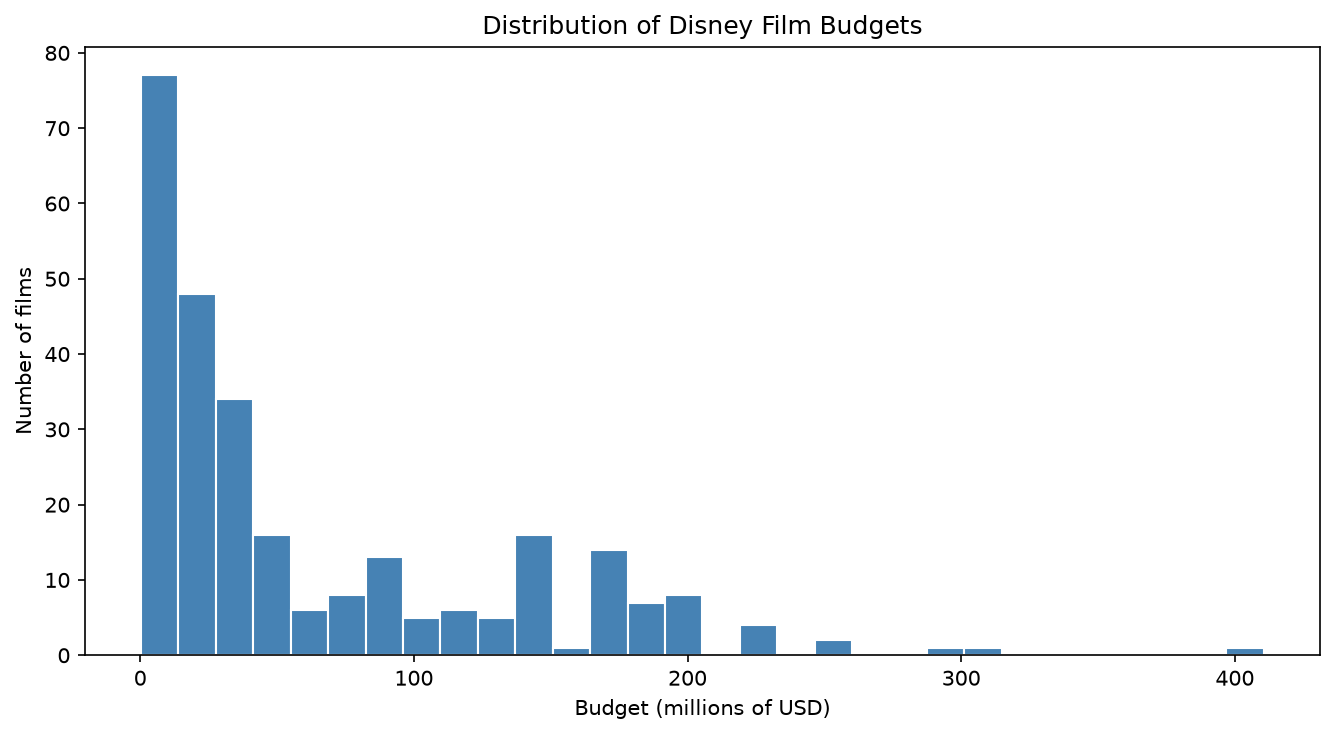

In [67]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.hist(disney["Budget (float)"].dropna() / 1e6, bins=30,
        color="steelblue", edgecolor="white")

ax.set_title("Distribution of Disney Film Budgets")
ax.set_xlabel("Budget (millions of USD)")
ax.set_ylabel("Number of films")

plt.tight_layout()
fig.savefig("figures/budget_histogram.png", dpi=300, bbox_inches="tight")
plt.show()

I then wanted to look more into how scores look overall. IMDb scores bunch up between about 60 and 75, while Rotten Tomatoes scores are all over the place. Metascores land in the middle. So the audience rates Disney movies pretty consistently, and critics disagree a lot more.

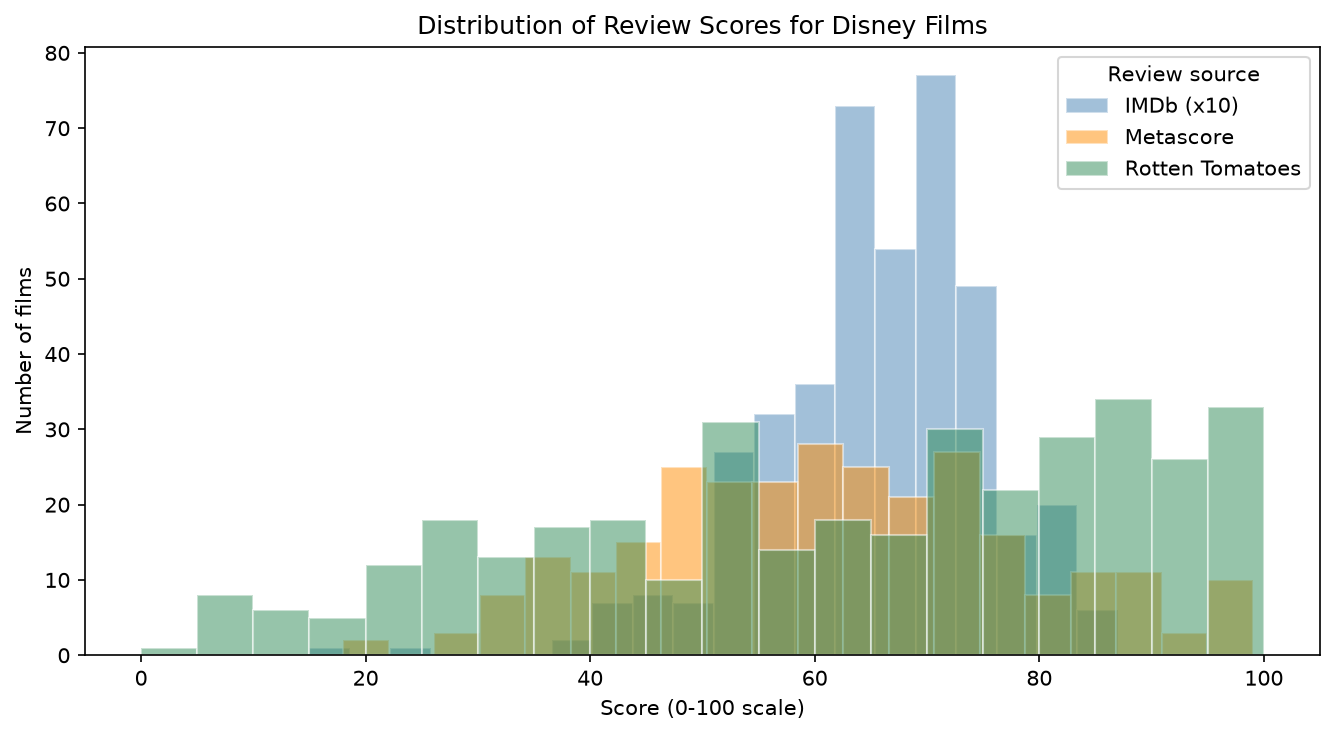

In [68]:
fig, ax = plt.subplots(figsize=(9, 5))

for col, label, color in [
    ("imdb", "IMDb (x10)", "steelblue"),
    ("metascore", "Metascore", "darkorange"),
    ("rotten_tomatoes", "Rotten Tomatoes", "seagreen"),
]:
    ax.hist(disney[col].dropna().astype(float), bins=20, alpha=0.5,
            label=label, color=color, edgecolor="white")

ax.set_title("Distribution of Review Scores for Disney Films")
ax.set_xlabel("Score (0-100 scale)")
ax.set_ylabel("Number of films")
ax.legend(title="Review source")

plt.tight_layout()
fig.savefig( "figures/ratings_histogram.png", dpi=300, bbox_inches="tight")
plt.show()

Finally, I looked at the budget and box office for each movie, and I identified on the graph if the film broke even. Most Disney movies made more at the box office than they cost, since most points sit above the break-even line. Bigger budgets tend to go with bigger box office totals, but only a small group of movies fell below the line. Box office is gross revenue, not profit. A movie just above the line may not have actually been profitable, if advertising and overhead costs are factored in.

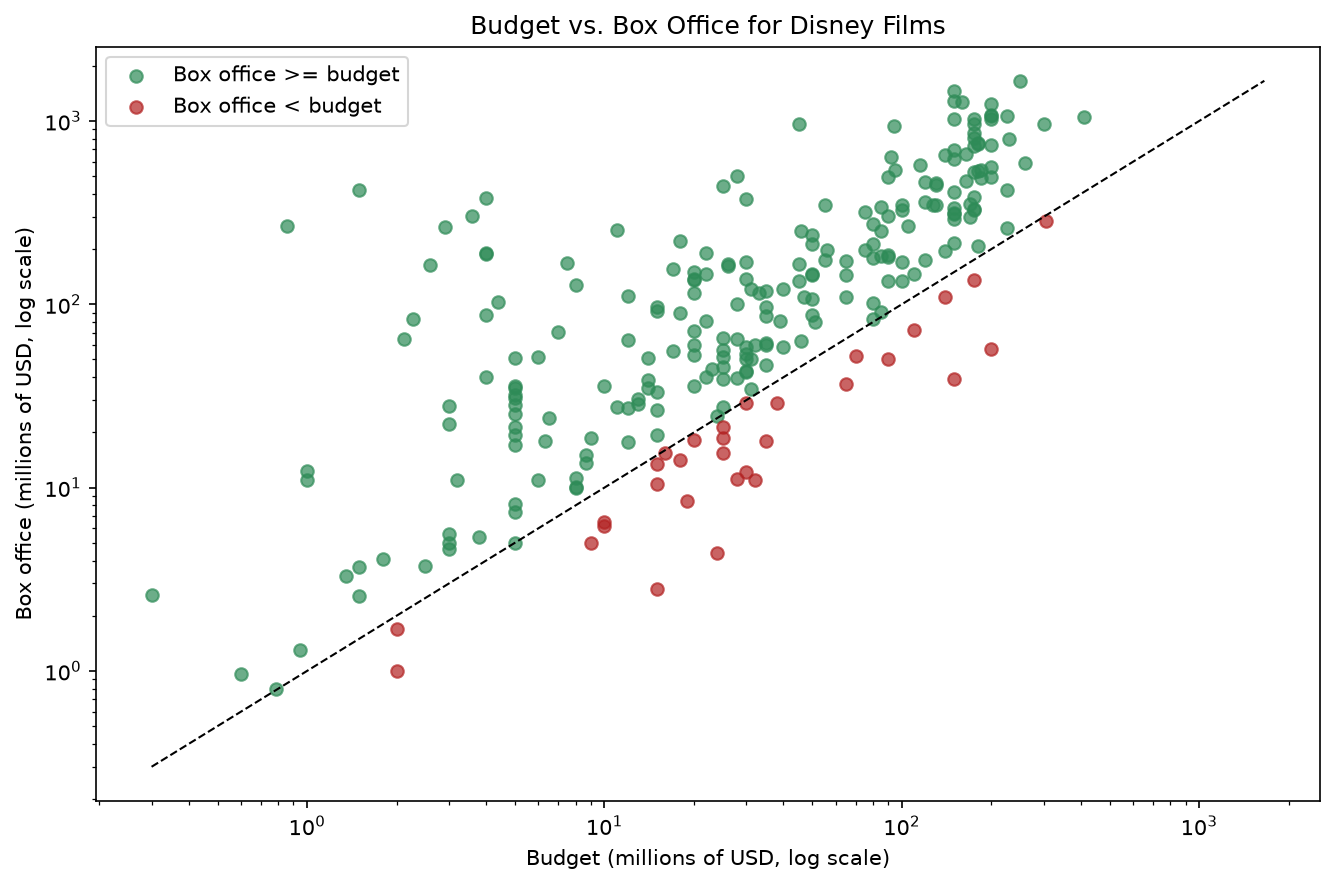

In [69]:
data = disney[["Budget (float)", "Box office (float)"]].dropna()
data = data[(data > 0).all(axis=1)] / 1e6

profit = data["Box office (float)"] >= data["Budget (float)"]

fig, ax = plt.subplots(figsize=(9, 6))

ax.scatter(data.loc[profit, "Budget (float)"], data.loc[profit, "Box office (float)"],
           color="seagreen", alpha=0.7, label="Box office >= budget")
ax.scatter(data.loc[~profit, "Budget (float)"], data.loc[~profit, "Box office (float)"],
           color="firebrick", alpha=0.7, label="Box office < budget")

lims = [data.min().min(), data.max().max()]
ax.plot(lims, lims, "k--", linewidth=1)

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_title("Budget vs. Box Office for Disney Films")
ax.set_xlabel("Budget (millions of USD, log scale)")
ax.set_ylabel("Box office (millions of USD, log scale)")
ax.legend(loc="upper left")

plt.tight_layout()
fig.savefig( "figures/budget_vs_boxoffice.png", dpi=300, bbox_inches="tight")
plt.show()